# Week 11: NLP

In this workshop you build a **RAG system**, retrieval-augmented generation, over every NUS module:

- **Section 1 - Intro to NLP and LLMs:** why text is hard for computers, how an LLM writes, and where it gets things wrong.
- **Section 2 - Retrieval Engine:** embeddings, chunking and semantic search over the NUSMods data.
- **Section 3 - Generation + Evaluation:** let Gemini answer from the retrieved modules, then measure how good the retrieval is.

Run the cells from top to bottom. Cells marked **YOUR TURN** are for you to edit.

# Section 1 - Intro to NLP and LLMs

By the end of this workshop you will have built a **RAG system**: a search engine over every NUS module, connected to an LLM that answers questions using what the search finds. This section lays the groundwork in three parts:

1. **Setup:** load the module data and connect your own Gemini API key.
2. **From text to numbers:** why text is hard for computers, what tokens are, and how an LLM actually writes.
3. **Where LLMs break:** ask Gemini about NUS modules, check its answers against the real data, and see why RAG is the fix.


## Setup

Run the two cells in this part now, while everyone is arriving.

On Colab, the first cell starts by downloading this week's folder from GitHub. Then it loads three things through `rag_utils.py`, a small helper file that all three sections share:

- `modules`: every module NUS offers in AY 2026-2027, taken from [NUSMods](https://nusmods.com). Each module is a Python dictionary with its code, title, description, workload and more. The organisers downloaded this in advance and saved it in `data/`, so the workshop does not depend on NUSMods being up.
- `embeddings`: one row of numbers per module. You will meet these in Section 2.
- `model`: `all-MiniLM-L6-v2`, a small model that turns text into numbers. It runs on your own CPU and needs no API key. The first run downloads it (about 90 MB).

In [129]:
# %pip install -q google-genai sentence-transformers numpy matplotlib
import json
import os
import re
import sys
import textwrap
import urllib.request
import warnings

# On Colab: download only the week-11-nlp folder of the workshop repo (a few seconds)
if "google.colab" in sys.modules:
    if not os.path.exists("/content/Sem-1"):
        !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/NUS-SDS-Workshops-AY2627/Sem-1.git /content/Sem-1
        !git -C /content/Sem-1 sparse-checkout set week-11-nlp
    %cd /content/Sem-1/week-11-nlp

os.environ["TRANSFORMERS_VERBOSITY"] = os.environ["HF_HUB_VERBOSITY"] = "error"  # hide harmless warnings
warnings.filterwarnings("ignore", message=".*HF_TOKEN.*")

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

import rag_utils
from rag_utils import build_chunk, keyword_search, search

modules, embeddings, model = rag_utils.load()
by_code = {module["moduleCode"]: module for module in modules}  # "CS4248" -> its record

print(f"{len(modules)} modules offered in AY {rag_utils.AY}, fetched from NUSMods on {rag_utils.FETCH_DATE}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6552 modules offered in AY 2026-2027, fetched from NUSMods on 2026-10-10


### Connect Gemini

Each of you needs your **own** free API key: the free quota is counted per Google Cloud project, so 40 people sharing one key would run out within minutes.

> **Your Gemini API key (one-time, about 2 minutes)**
> 1. Go to **[aistudio.google.com/apikey](https://aistudio.google.com/apikey)**, sign in with a *personal* Google account, find the 🔑 icon, click **Create API key** and copy the key. It's free — **don't** set up billing, because that turns the free tier off for the project.
> 2. In Colab, click the **key icon 🔑 (Secrets)** in the left sidebar → **Add new secret**.
> 3. Name: `GEMINI_API_KEY` · Value: paste your key · switch **Notebook access** on.
>
> No secret set up? The next cell asks you to paste the key instead. Never type your key into the code itself: it would be saved inside the notebook, and anyone you share the notebook with could use up your quota.

The cell below connects `ask_gemini` (from `rag_utils.py`), the one function we use to talk to Gemini. It sends your prompt and nothing else: no extra documents, and no Google Search. If the call fails, for example because the free quota has run out, it prints the reason and returns a saved answer instead of crashing.

In [130]:
from rag_utils import ask_gemini

# Looks for your key in Colab Secrets first, then asks you to paste it.
rag_utils.connect_gemini()

print("Gemini says:", ask_gemini("Reply with exactly: ready"))

Gemini says: ready


You should see `Gemini says: ready`. If you see `Gemini call failed` instead, the message tells you why. The most common one is `API key not valid`: copy the key again, update the secret, and re-run the cell. If it still fails, raise your hand. You can follow the Gemini demos on the main screen in the meantime.

## 1.1 Reading text

How does a computer read text? Computers only understand numbers, so we have to turn words into numbers. That is hard, because text is:

- **Messy:** punctuation, capital letters, hyphens, and codes like `CS3244`.
- **Ambiguous:** the same word can mean different things, and different words can mean the same thing.

NLP deals with this through a pipeline. We walk through it in this section and finish it in Section 2:


Our example all the way through is one real NUSMods description, the first sentence of **CS3244 Machine Learning**:

> This course introduces basic concepts and algorithms in machine learning and neural networks.

In [131]:
module = by_code["CS3244"]
sentence = module["description"].split(". ")[0] + "."

print(module["moduleCode"], "-", module["title"])
print(sentence)
print()

# Turning each character into a number is easy...
print([ord(character) for character in "CS3244"])

# ...but the meaning is not in the characters
print("course" == "module")      # same meaning: the description says course, NUSMods says module
print("networks" == "networks")  # same characters: neural networks (CS3244) or computer networks (CS2105)?

CS3244 - Machine Learning
This course introduces basic concepts and algorithms in machine learning and neural networks.

[67, 83, 51, 50, 52, 52]
False
True


## 1.2 Preprocessing

Before a computer can count or compare words, we clean the text up. Each step changes the CS3244 sentence a little:

| Step | What it does |
|---|---|
| Cleaning | remove punctuation and symbols |
| Tokenization | split into words |
| Lowercasing | make every letter lowercase |
| Stopword removal | drop common words such as "this", "and", "in" |
| Stemming | chop off word endings |
| Lemmatization | turn words back into their dictionary form |

The last four steps together are called **normalization**: they make different forms of the same word look alike.

In [132]:
STOPWORDS = {"a", "an", "and", "are", "as", "at", "be", "by", "for", "from", "in", "is", "of", "on", "or", "some", "the", "this", "to", "with"}

# Real lemmatizers look words up in a full English dictionary. Ours only knows a few words.
LEMMAS = {"introduces": "introduce", "concepts": "concept", "algorithms": "algorithm", "networks": "network",
          "computers": "computer", "systems": "system", "tasks": "task", "students": "student"}


def preprocess(text):
    """Run each preprocessing step on the text and print the result."""
    cleaned = re.sub(r"[^\w\s]", "", text)                         # remove punctuation and symbols
    words = cleaned.split()                                        # split into words
    lowered = [word.lower() for word in words]                     # make every letter lowercase
    kept = [word for word in lowered if word not in STOPWORDS]     # drop common words
    stems = [re.sub(r"(ing|es|s|e)$", "", word) for word in kept]  # chop off a common ending
    lemmas = [LEMMAS.get(word, word) for word in kept]             # look up the dictionary form

    for step, result in [("Raw text", text), ("Cleaning", cleaned), ("Tokenization", words),
                         ("Lowercasing", lowered), ("Stopword removal", kept),
                         ("Stemming", stems), ("Lemmatization", lemmas)]:
        print(f"{step:<17} {result}")


preprocess(sentence)

Raw text          This course introduces basic concepts and algorithms in machine learning and neural networks.
Cleaning          This course introduces basic concepts and algorithms in machine learning and neural networks
Tokenization      ['This', 'course', 'introduces', 'basic', 'concepts', 'and', 'algorithms', 'in', 'machine', 'learning', 'and', 'neural', 'networks']
Lowercasing       ['this', 'course', 'introduces', 'basic', 'concepts', 'and', 'algorithms', 'in', 'machine', 'learning', 'and', 'neural', 'networks']
Stopword removal  ['course', 'introduces', 'basic', 'concepts', 'algorithms', 'machine', 'learning', 'neural', 'networks']
Stemming          ['cours', 'introduc', 'basic', 'concept', 'algorithm', 'machin', 'learn', 'neural', 'network']
Lemmatization     ['course', 'introduce', 'basic', 'concept', 'algorithm', 'machine', 'learning', 'neural', 'network']


Stemming is fast but crude: `cours` and `machin` are not words. Lemmatization gives real words, but only for words its dictionary knows.

**YOUR TURN:** run the same steps on another sentence. The default is the third sentence of the CS3244 description: look at what cleaning does to `self-learning`, and what stemming does to `programming`. Then try a sentence from a module you have taken, for example `by_code["CS2040S"]["description"]`.

In [133]:
# YOUR TURN: change the sentence, then re-run
my_sentence = "The ultimate objective is to build self-learning systems to relieve human from some of already-too-many programming tasks."

preprocess(my_sentence)

Raw text          The ultimate objective is to build self-learning systems to relieve human from some of already-too-many programming tasks.
Cleaning          The ultimate objective is to build selflearning systems to relieve human from some of alreadytoomany programming tasks
Tokenization      ['The', 'ultimate', 'objective', 'is', 'to', 'build', 'selflearning', 'systems', 'to', 'relieve', 'human', 'from', 'some', 'of', 'alreadytoomany', 'programming', 'tasks']
Lowercasing       ['the', 'ultimate', 'objective', 'is', 'to', 'build', 'selflearning', 'systems', 'to', 'relieve', 'human', 'from', 'some', 'of', 'alreadytoomany', 'programming', 'tasks']
Stopword removal  ['ultimate', 'objective', 'build', 'selflearning', 'systems', 'relieve', 'human', 'alreadytoomany', 'programming', 'tasks']
Stemming          ['ultimat', 'objectiv', 'build', 'selflearn', 'system', 'reliev', 'human', 'alreadytoomany', 'programm', 'task']
Lemmatization     ['ultimate', 'objective', 'build', 'selflearning', 's

Cleaning glued `self-learning` into one word, `selflearning`. Every step throws a little information away, so each one is a trade-off.

These steps prepare text for counting words, which you will meet as TF-IDF in Section 2. Modern language models skip most of them and read text as **tokens** instead.

## 1.3 Tokens

A **token** is a fundamental chunk of text that a language model processes. Splitting on spaces, as in 1.2, is the simplest way to get tokens, but language models use smarter rules:

- Common words are usually 1 token.
- Rare words and codes get split into smaller pieces the model has seen before. On the slides, `CS3244` becomes `CS | 324 | 4`.

Every model comes with its own **tokenizer** that does this splitting, and each one splits a little differently. Here is the tokenizer of `all-MiniLM-L6-v2` reading the full CS3244 description.

In [134]:
module = by_code["CS3244"]
text = module["description"]

print(module["moduleCode"], "-", module["title"])
print(textwrap.fill(text, 100))
print()

tokens = model.tokenizer.tokenize(text)
print(f"{len(text.split())} words -> {len(tokens)} tokens")
print(tokens)

CS3244 - Machine Learning
This course introduces basic concepts and algorithms in machine learning and neural networks. The
main reason for studying computational learning is to make better use of powerful computers to learn
knowledge (or regularities) from the raw data. The ultimate objective is to build self-learning
systems to relieve human from some of already-too-many programming tasks. At the end of the course,
students are expected to be familiar with the theories and paradigms of computational learning, and
capable of implementing basic learning systems.

81 words -> 97 tokens
['this', 'course', 'introduces', 'basic', 'concepts', 'and', 'algorithms', 'in', 'machine', 'learning', 'and', 'neural', 'networks', '.', 'the', 'main', 'reason', 'for', 'studying', 'computational', 'learning', 'is', 'to', 'make', 'better', 'use', 'of', 'powerful', 'computers', 'to', 'learn', 'knowledge', '(', 'or', 'regular', '##ities', ')', 'from', 'the', 'raw', 'data', '.', 'the', 'ultimate', 'objectiv

**YOUR TURN:** alter the words in the list and re-run to see what MiniLM's tokenizer gives. The list starts with words and codes from CS3244, and ends with two oddities from other NUSMods descriptions. Try other module codes, your name, Singlish, or another language.

In [135]:
# YOUR TURN: alter the words, then re-run
my_words = [
    # from the CS3244 description
    "machine", "regularities", "paradigms", "self-learning",
    # CS3244 and two of its prerequisites
    "CS3244", "CS2040S", "ST2334",
    # oddities from the FIN3702A and CL3211 descriptions
    "eﬃciency", "汉语拼音方案",
]

for word in my_words:
    print(f"{word:>15} -> {model.tokenizer.tokenize(word)}")

# Each token is really an ID number in the model's vocabulary
print()
print("Token IDs:", model.tokenizer.encode("machine learning and neural networks", add_special_tokens=False))

        machine -> ['machine']
   regularities -> ['regular', '##ities']
      paradigms -> ['paradigm', '##s']
  self-learning -> ['self', '-', 'learning']
         CS3244 -> ['cs', '##32', '##44']
        CS2040S -> ['cs', '##20', '##40', '##s']
         ST2334 -> ['st', '##23', '##34']
       eﬃciency -> ['[UNK]']
         汉语拼音方案 -> ['[UNK]', '[UNK]', '[UNK]', '[UNK]', '方', '[UNK]']

Token IDs: [3698, 4083, 1998, 15756, 6125]


MiniLM lowercases everything first. `##` marks a piece that continues the word before it, so `regularities` becomes `regular` + `##ities`. `[UNK]` means **unknown**: the character is not in the model's vocabulary at all. `eﬃciency` looks normal, but its "ﬃ" is one special character (probably copied from a PDF), so MiniLM cannot read the word. That is messy text in action.

The IDs on the last line are what the model actually receives.

### The token budget

A model can only read a limited number of tokens at once: its **token budget**. Anything past the budget gets cut off, and the model never sees it. Change `budget` below and re-run to see where the CS3244 description gets cut.

In [136]:
# Try it: change the budget, then re-run
budget = 10

print(f"Read ({budget} tokens):", model.tokenizer.convert_tokens_to_string(tokens[:budget]))
print()
print(f"Cut off ({len(tokens[budget:])} tokens):", model.tokenizer.convert_tokens_to_string(tokens[budget:]))

Read (10 tokens): this course introduces basic concepts and algorithms in machine learning

Cut off (87 tokens): and neural networks. the main reason for studying computational learning is to make better use of powerful computers to learn knowledge ( or regularities ) from the raw data. the ultimate objective is to build self - learning systems to relieve human from some of already - too - many programming tasks. at the end of the course, students are expected to be familiar with the theories and paradigms of computational learning, and capable of implementing basic learning systems.


With the default budget of 10, the model would never learn that CS3244 covers neural networks. Real budgets are bigger, but so is real text. Here is MiniLM's budget, checked against every NUSMods description:

In [137]:
limit = model.max_seq_length
description_lengths = [len(model.tokenizer.tokenize(m["description"])) for m in modules]
longest = int(np.argmax(description_lengths))

print(f"MiniLM reads at most {limit} tokens")
print(f"CS3244 description: {len(tokens)} tokens")
print(f"Longest description: {description_lengths[longest]} tokens ({modules[longest]['moduleCode']})")
print(f"Descriptions over the limit: {sum(n > limit for n in description_lengths)} of {len(modules)}")

# Gemini uses a different tokenizer, so the same text gives a different count
try:
    gemini_count = rag_utils.gemini_client().models.count_tokens(model=rag_utils.GEMINI_MODEL, contents=text).total_tokens
    print(f"\nThe CS3244 description: MiniLM = {len(tokens)} tokens, Gemini = {gemini_count} tokens")
except Exception:
    pass

MiniLM reads at most 256 tokens
CS3244 description: 97 tokens
Longest description: 830 tokens (GMS5224)
Descriptions over the limit: 70 of 6552

The CS3244 description: MiniLM = 97 tokens, Gemini = 97 tokens


## 1.4 How an LLM works

How does an **LLM** (large language model) deal with words? One token at a time:

1. It predicts the next token based on **all the tokens before it**.
2. It picks a likely token, adds it to the text, and repeats.

It is trained to sound **likely**, not to be **true**. That makes it fluent, but also easy to hallucinate.

To watch it happen, we load a tiny LLM called **SmolLM2**. It has 135 million parameters, small enough to run on a laptop CPU (about a 270 MB download). Gemini works the same way, just thousands of times bigger.

In [138]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

LM_NAME = "HuggingFaceTB/SmolLM2-135M"
lm_tokenizer = AutoTokenizer.from_pretrained(LM_NAME)
lm = AutoModelForCausalLM.from_pretrained(LM_NAME)
lm.eval()


def show_next_tokens(prompt, k=5):
    """Show the model's top k guesses for the very next token."""
    ids = lm_tokenizer(prompt, return_tensors="pt").input_ids
    with torch.no_grad():
        probabilities = torch.softmax(lm(ids).logits[0, -1], dim=-1)
    top = torch.topk(probabilities, k)
    print(f"{prompt!r} ...")
    for probability, token_id in zip(top.values, top.indices):
        token = lm_tokenizer.decode([int(token_id)])
        print(f"   {token!r:<16} {probability.item():6.1%}  " + "#" * int(probability.item() * 40))


def generate_step_by_step(prompt, n=15):
    """Generate n tokens one at a time, always picking the most likely one."""
    ids = lm_tokenizer(prompt, return_tensors="pt").input_ids
    for step in range(n):
        with torch.no_grad():
            next_id = int(lm(ids).logits[0, -1].argmax())
        ids = torch.cat([ids, torch.tensor([[next_id]])], dim=1)
        print(f"step {step + 1:>2}: + {lm_tokenizer.decode([next_id])!r}")
    print()
    print("Full text:", lm_tokenizer.decode(ids[0], skip_special_tokens=True))


show_next_tokens("This course introduces basic concepts and algorithms in")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

'This course introduces basic concepts and algorithms in' ...
   ' computer'        8.3%  ###
   ' the'             8.3%  ###
   ' data'            5.4%  ##
   ' machine'         4.7%  #
   ' graph'           3.1%  #


These are SmolLM2's top 5 guesses for the token that comes after the start of the CS3244 sentence. The real next word is `machine`. Now give the model more of the sentence, and watch the guesses change.

In [139]:
show_next_tokens("This course introduces basic concepts and algorithms in machine")
show_next_tokens("This course introduces basic concepts and algorithms in machine learning and neural")

'This course introduces basic concepts and algorithms in machine' ...
   ' learning'       97.7%  #######################################
   ' vision'          1.0%  
   ' intelligence'    0.3%  
   ' translation'     0.1%  
   ' perception'      0.1%  
'This course introduces basic concepts and algorithms in machine learning and neural' ...
   ' networks'       93.0%  #####################################
   ' network'         4.6%  #
   ' nets'            0.8%  
   ' networking'      0.3%  
   ' processing'      0.2%  


The more tokens come before, the surer the model gets. Now let it keep going from the shorter prompt. At every step it takes the most likely token and adds it to the text.

In [140]:
generate_step_by_step("This course introduces basic concepts and algorithms in", n=20)

step  1: + ' the'
step  2: + ' field'
step  3: + ' of'
step  4: + ' computer'
step  5: + ' science'
step  6: + '.'
step  7: + ' It'
step  8: + ' covers'
step  9: + ' topics'
step 10: + ' such'
step 11: + ' as'
step 12: + ' algorithms'
step 13: + ','
step 14: + ' data'
step 15: + ' structures'
step 16: + ','
step 17: + ' and'
step 18: + ' programming'
step 19: + ' languages'
step 20: + '.'

Full text: This course introduces basic concepts and algorithms in the field of computer science. It covers topics such as algorithms, data structures, and programming languages.


It reads smoothly, and it sounds like a real course description. But it is not CS3244: the real description continues with *machine learning and neural networks*. The model aims for text that sounds likely, and that is not the same as text that is true.

What happens when we ask about something the model cannot possibly know?

In [141]:
show_next_tokens("The NUS module CS3244 is titled")
generate_step_by_step("The NUS module CS3244 is titled", n=15)

print()
print("Real title:", by_code["CS3244"]["title"])

'The NUS module CS3244 is titled' ...
   ' “'              24.5%  #########
   ' "'              21.7%  ########
   ' ‘'               6.2%  ##
   " '"               4.8%  #
   ':'                3.8%  #
step  1: + ' “'
step  2: + 'The'
step  3: + ' History'
step  4: + ' of'
step  5: + ' the'
step  6: + ' Internet'
step  7: + '”'
step  8: + ' and'
step  9: + ' is'
step 10: + ' a'
step 11: + ' course'
step 12: + ' in'
step 13: + ' the'
step 14: + ' history'
step 15: + ' of'

Full text: The NUS module CS3244 is titled “The History of the Internet” and is a course in the history of

Real title: Machine Learning


## 1.5 Where LLMs break

When we use an LLM to look something up, it might:

- **not know the updated data**, because of its **knowledge cutoff**: it only knows what it was trained on, up to a certain date.
- **invent fluent but untrue facts**, because of **next-token prediction**: it picks what sounds likely, not what is true.

Confident answers that are wrong are called **hallucinations**. SmolLM2 is tiny. Does a real model do better? We will ask Gemini about NUS modules, giving it **no extra information**, and then **check its answer** against the real NUSMods data.

`verify` does the checking. It finds every module code in an answer, such as `CS3244`, and looks it up in this year's module list.

In [142]:
MODULE_CODE = re.compile(r"\b[A-Z]{2,4}\d{4}[A-Z]{0,2}\b")  # e.g. CS3244, CS2040S


def verify(answer):
    """Look up every module code in the answer in the real NUSMods data."""
    codes = list(dict.fromkeys(MODULE_CODE.findall(answer)))  # unique, in order
    for code in codes:
        real = by_code.get(code)
        if real:
            print(f"  ✅ {code:<9} real title: {real['title']}")
        else:
            print(f"  ❌ {code:<9} not offered in AY {rag_utils.AY}, or does not exist")
        said = next(line for line in answer.splitlines() if code in line)  # where Gemini mentioned it
        print(f"{'':15}Gemini wrote: {textwrap.shorten(re.sub(r'[*_#`|>]', '', said), 90)}")
    print()
    print(f"{sum(code in by_code for code in codes)} of {len(codes)} module codes are real.")

### Ask, then verify

First, the question. Gemini sees only this sentence.

In [143]:
question = "Which NUS modules cover attention mechanisms? List the module codes and titles."

answer = ask_gemini(question)
display(Markdown(answer))

At the National University of Singapore (NUS), attention mechanisms—a foundational concept in modern deep learning, transformers, and Large Language Models (LLMs)—are primarily covered in Computer Science and Data Science modules focusing on Machine Learning, Deep Learning, and Natural Language Processing (NLP). 

Here are the NUS modules that explicitly or extensively cover attention mechanisms:

### **Undergraduate / Graduate Modules**

*   **CS4248** – Natural Language Processing
    *   *Coverage:* Covers traditional NLP as well as modern deep learning approaches for text, including recurrent neural networks (RNNs), sequence-to-sequence models, and the introduction of attention mechanisms and Transformer architectures.
*   **CS5340** – Uncertainty Modeling in Artificial Intelligence (or related advanced ML variants) / **CS5446** – AI Planning and Decision Making *(Note: Deep learning modules change codes frequently, but CS4/5k machine learning electives heavily feature this)*.
*   **CS5242** – Neural Networks and Deep Learning
    *   *Coverage:* This is the core graduate-level deep learning module. It typically covers CNNs, RNNs, and delves deep into the Transformer architecture, self-attention, multi-head attention, and their applications in both computer vision and NLP.
*   **CS5485** – Advanced Machine Learning
    *   *Coverage:* Often touches upon advanced architectures, graph neural networks, and attention-based models depending on the semester's focus.
*   **EE5907** – Pattern Recognition or **EE4305** – Introduction to Fuzzy Systems and Neural Networks (Department of Electrical and Computer Engineering)
    *   *Coverage:* ECE department modules that deal with computer vision and pattern recognition frequently incorporate Vision Transformers (ViTs) and spatial/channel attention mechanisms (like SENet).

### **Data Science & AI Specific Modules**
*   **DSA4211** – Deep Learning for Data Science (or equivalent departmental code)
    *   *Coverage:* Practical implementation of deep learning models, where students build models utilizing attention layers using PyTorch/TensorFlow.

---

### **Recommendation for Students:**
If you want the **most thorough and direct coverage** of attention mechanisms (Transformers, Self-Attention, Cross-Attention), you should look at:
1. **CS5242** (Neural Networks and Deep Learning) – Best for understanding the mathematical and structural mechanics of attention.
2. **CS4248** (Natural Language Processing) – Best for understanding how attention revolutionized text and sequence modeling. 

*(Note: NUS frequently updates its module codes and introduces new Special Topics modules (such as CS5329 or similar experimental codes) specifically for Large Language Models and Generative AI, which are entirely centered around attention mechanisms. Always check the current CORS/ModReg or department website for the latest syllabi.)*

We verify the answer in the following block. 

In [144]:
verify(answer)

  ✅ CS4248    real title: Introduction to Large Language Models
               Gemini wrote: CS4248 – Natural Language Processing
  ✅ CS5340    real title: Uncertainty Modelling in AI
               Gemini wrote: CS5340 – Uncertainty Modeling in Artificial Intelligence (or related advanced ML [...]
  ✅ CS5446    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: CS5340 – Uncertainty Modeling in Artificial Intelligence (or related advanced ML [...]
  ✅ CS5242    real title: Neural Networks and Deep Learning
               Gemini wrote: CS5242 – Neural Networks and Deep Learning
  ❌ CS5485    not offered in AY 2026-2027, or does not exist
               Gemini wrote: CS5485 – Advanced Machine Learning
  ✅ EE5907    real title: Pattern Recognition
               Gemini wrote: EE5907 – Pattern Recognition or EE4305 – Introduction to Fuzzy Systems and Neural [...]
  ❌ EE4305    not offered in AY 2026-2027, or does not exist
               Gemini w

**How to read it:**

- ❌ means the code is not in this year's NUSMods data. Either the module does not exist, or it is not running this year.
- ✅ with a different title means the code is real, but Gemini attached the wrong module to it, or used an old name.
- ✅ with a matching title means Gemini got that one right. You only know because you checked.

### Numbers it could easily invent

Specific numbers are the easiest thing for an LLM to get plausibly wrong. NUSMods lists the weekly workload of every module in hours.

In [145]:
module_code = "CS3244"
workload_question = (f"What is the weekly workload of NUS module {module_code} in hours, "
                     "as lecture / tutorial / lab / project / preparation?")

print("GEMINI SAYS:")
print(ask_gemini(workload_question))
print()
print("NUSMODS SAYS:", rag_utils.format_workload(by_code.get(module_code, {}).get("workload")) or "(not listed)")

GEMINI SAYS:
Based on the official National University of Singapore (NUS) module structure for **CS3244 (Machine Learning)**, the workload is categorized under the standard 8-unit or 4-credit system (depending on the curriculum year, but typically structured as an 8-hour total workload per week for a 4-MC module). 

Here is the typical breakdown of the weekly workload in hours:

*   **Lectures:** 3 hours per week
*   **Tutorials:** 1 hour per week (usually held on alternate weeks or weekly depending on the semester, but officially budgeted as 1 hour)
*   **Lab / Practical:** 0 hours (CS3244 does not have formal supervised lab hours; programming is done independently)
*   **Project Work:** ~3 to 4 hours per week (CS3244 features a substantial semester-long machine learning project, usually done in groups)
*   **Preparation / Self-Study:** ~3 to 5 hours per week (reviewing lecture notes, reading academic papers/textbook chapters, and preparing for assignments/tests)

### **Total Weekly W

Hours per week that look reasonable are exactly what next-token prediction produces, whether or not they are true.

Now paste the CS3244 entry from NUSMods into the prompt and ask the same question again.

In [146]:
entry = build_chunk(by_code.get(module_code, {}))  # code, title, description and workload from NUSMods

print("GEMINI SAYS, WITH THE NUSMODS ENTRY:")
print(ask_gemini(f"Answer using only this entry from NUSMods.\n\n{entry}\n\n{workload_question}"))

GEMINI SAYS, WITH THE NUSMODS ENTRY:
Based on the NUSMods entry provided, the workload is:

* Lecture: 2h
* Tutorial: 1h
* Lab: Not mentioned
* Project: 4h
* Preparation: 3h


With the entry in front of it, Gemini only has to read the answer off, and you know where the answer came from: NUSMods. Hold on to that idea, because it is the core of 1.6. Try a module you have taken, such as `CS2040S` or `ST2334` (two of CS3244's prerequisites), and re-run both cells.

### Right last year, wrong this year

**Context:** a module's *preclusions* are modules that overlap with it so much that you cannot take both. NUSMods updates the list every year, and the AY 2026-2027 list for CS3244 is longer than the AY 2025-2026 one.

In [147]:
import requests

module_code = "CS3244"
print("GEMINI SAYS:", ask_gemini(f"Which modules are precluded for the NUS module {module_code}? Reply with the module codes only."))

for ay in ["2025-2026", rag_utils.AY]:
    response = requests.get(f"https://api.nusmods.com/v2/{ay}/modules/{module_code}.json", timeout=30)
    preclusion = response.json().get("preclusion") or ""
    print(f"NUSMODS AY {ay}:", ", ".join(dict.fromkeys(MODULE_CODE.findall(preclusion))))

GEMINI SAYS: CS4248, IT5006
NUSMODS AY 2025-2026: BT4240, CG3201, CS2109S, CS3264, DMX1401AI, IT3011
NUSMODS AY 2026-2027: BT4240, CG3201, CS2109HS, CS2109S, CS3264, DMX1401AI, EE3703, EE4802, IT3011


Compare the two NUSMods lines: this year's list has codes that last year's did not. Unless Gemini's training data happened to include this year's list, it cannot know them. That is the knowledge cutoff.

**YOUR TURN:** ask Gemini your own question about NUS modules, then check it. Ask for module codes, so that `verify` has something to check. Some things to try:

- A topic from the CS3244 description: *"Which NUS modules teach neural networks?"*
- What comes next: *"Which NUS modules should I take after CS3244?"*
- A module you have taken: *"What is CS2040S about, and what modules come after it?"*

In [148]:
# YOUR TURN: ask your own question, then re-run
my_question = "Which NUS modules should I take after CS3244 Machine Learning? List the module codes and titles."

my_answer = ask_gemini(my_question)
display(Markdown(my_answer))
print("-" * 60)
verify(my_answer)

Following **CS3244 Machine Learning**, the National University of Singapore (NUS) offers a wide range of more advanced, specialized, and application-oriented modules in Machine Learning, Artificial Intelligence, Data Science, and related fields. 

Depending on your specific interests (e.g., Deep Learning, Natural Language Processing, Reinforcement Learning, or Theory), here are the recommended modules you can take next, categorized by sub-fields:

### 1. Advanced Machine Learning & Deep Learning (Direct Continuations)
These modules dive deeper into specific architectures, algorithms, and the theoretical underpinnings of modern AI.
* **CS4246** – AI: Uncertainty and Reasoning *(Focuses on probabilistic graphical models and decision-making under uncertainty)*
* **CS5340** – Uncertainty Modeling in Artificial Intelligence *(Graduate-level, deep dive into probabilistic models)*
* **CS5242** – Neural Networks and Deep Learning *(The quintessential follow-up if you want to master CNNs, RNNs, Transformers, and modern neural architectures)*

### 2. Specialized AI Domains
If you want to apply machine learning to specific types of data or problem spaces:
* **CS4248** – Natural Language Processing *(Focuses on text data, LLMs, sentiment analysis, and language generation)*
* **CS3243** – Introduction to Artificial Intelligence *(Note: Some students take this before CS3244, but it can be taken after; covers search, logic, and classical AI)*
* **CS4243** – Computer Vision and Pattern Recognition *(Focuses on image and video processing using ML/DL)*
* **CS4239** – Principles of Information Security *(Uses ML for security applications, though more security-focused)*

### 3. Decision Making & Reinforcement Learning
* **CS5446** – AI Planning and Decision Making *(Covers automated planning, Markov Decision Processes, and foundational Reinforcement Learning)*
* **CS5448** – Deep Reinforcement Learning *(Advanced module focusing on Q-learning, policy gradients, and actor-critic methods)*

### 4. Data Science & Systems (Heavy ML overlap)
If you are interested in the infrastructure behind ML or large-scale data processing:
* **CS4225** – Big Data Systems for Data Science *(Teaches how to scale ML models using tools like Hadoop and Spark)*
* **CS3229** – Applied Analytics Infrastructure *(More focused on the data engineering side of analytics)*
* **ST3131** – Regression Analysis *(Provides a deeper statistical foundation for modeling)*
* **ST4240** – Data Mining *(Complementary statistical approaches to pattern discovery)*

### Recommendation on what to take next:
* If you want to learn **ChatGPT-style AI and Neural Networks**: Take **CS5242** (or check if your cohort has a newer 4000-level equivalent).
* If you want to work with **Text and Language**: Take **CS4248**.
* If you want to work with **Images and Video**: Take **CS4243**.
* If you want a **stronger theoretical/statistical foundation**: Look into Department of Statistics modules like **ST3131** or advanced **ST** data science modules. 

*Note: Always check NUSMods for the most up-to-date prerequisite requirements, as some 4000/5000-level modules may require strong mathematical foundations in linear algebra (e.g., MA1101R/MA2101) and calculus/probability (e.g., ST2131).*

------------------------------------------------------------
  ✅ CS3244    real title: Machine Learning
               Gemini wrote: Following CS3244 Machine Learning, the National University of Singapore (NUS) offers [...]
  ✅ CS4246    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: CS4246 – AI: Uncertainty and Reasoning (Focuses on probabilistic graphical models [...]
  ✅ CS5340    real title: Uncertainty Modelling in AI
               Gemini wrote: CS5340 – Uncertainty Modeling in Artificial Intelligence (Graduate-level, deep dive [...]
  ✅ CS5242    real title: Neural Networks and Deep Learning
               Gemini wrote: CS5242 – Neural Networks and Deep Learning (The quintessential follow-up if you want [...]
  ✅ CS4248    real title: Introduction to Large Language Models
               Gemini wrote: CS4248 – Natural Language Processing (Focuses on text data, LLMs, sentiment [...]
  ✅ CS3243    real title: Introduction to Artificia

## 1.6 The RAG idea

**Retrieval-Augmented Generation (RAG)** is a framework that improves an LLM by connecting it to an external knowledge source. Ours is NUSMods:

```
 ┌──────┐  (1) ask      ┌─────────┐   (2) query     ┌──────────────────┐
 │      │ ────────────> │         │ ──────────────> │                  │
 │ User │               │ Chatbot │                 │ Knowledge source │
 │      │ <──────────── │  (LLM)  │ <────────────── │    (NUSMods)     │
 └──────┘ (4) response  └─────────┘  (3) knowledge  └──────────────────┘
```

### Why not paste all of NUSMods into the prompt?

Because of the token budget. `build_chunk` turns one module into the text we would paste, like the CS3244 entry in 1.5. The cell below counts tokens with MiniLM's tokenizer, so treat the numbers as estimates.

In [149]:
chunks = [build_chunk(m) for m in modules]
chunk_lengths = [len(ids) for ids in model.tokenizer(chunks, verbose=False)["input_ids"]]

print(f"CS3244 alone: about {chunk_lengths[modules.index(by_code['CS3244'])]} tokens")
print(f"All {len(modules)} modules: about {sum(chunk_lengths):,} tokens, in every single prompt")
print(f"5 relevant modules: about {sum(chunk_lengths[:5]):,} tokens")

try:
    gemini_limit = rag_utils.gemini_client().models.get(model=rag_utils.GEMINI_MODEL).input_token_limit
    print(f"{rag_utils.GEMINI_MODEL} reads at most {gemini_limit:,} tokens per prompt")
except Exception:
    pass

CS3244 alone: about 123 tokens
All 6552 modules: about 864,566 tokens, in every single prompt
5 relevant modules: about 792 tokens
gemini-3.5-flash-lite reads at most 1,048,576 tokens per prompt


All of NUSMods would fill most of the budget, if it fits at all, and every single question would pay for it again, when an answer needs only a handful of modules. **So fetch only the few modules that matter, and let the LLM answer from those.** That is **RAG**, retrieval-augmented generation:

```
 ┌─────────────┐     ┌─────────────┐     ┌────────────────────┐     ┌───────────────┐
 │ 1. Question │ ──> │ 2. Retrieve │ ──> │ 3. Augment         │ ──> │ 4. Generate   │
 │  from user  │     │  top-k most │     │  question + those  │     │  LLM answers  │
 │             │     │  relevant   │     │  modules -> prompt │     │  FROM them,   │
 │             │     │  modules    │     │                    │     │  with sources │
 └─────────────┘     └─────────────┘     └────────────────────┘     └───────────────┘
                       Section 2           Section 3                  Section 3
```

### The search process

RAG has to find the right modules first (step 2). The simplest way is **keyword search**: return every module whose title contains your exact words, like the search bar on NUSMods. Search for "machine learning":

In [150]:
def title_search(query):
    """Modules whose title contains the query, word for word."""
    return [module for module in modules if query.lower() in module["title"].lower()]


found = {module["moduleCode"] for module in title_search("machine learning")}
print(f'"machine learning" in the title: {len(found)} modules')
for code in ["CS3244", "AIS5103"]:
    print(f"    {'found  ' if code in found else 'MISSING'}  {code:<9} {by_code[code]['title']}")

print()
print("AIS5103 description:")
print(textwrap.fill(by_code["AIS5103"]["description"], 100))

"machine learning" in the title: 61 modules
    found    CS3244    Machine Learning
    MISSING  AIS5103   Foundations of Deep Learning

AIS5103 description:
This course presents the mathematical and computational foundations of machine learning with an
emphasis on deep learning networks, preparing the students with sufficient background for more
advanced topics such as AI in physics or any of the other sciences. The learning outcomes include
sufficient familiarity with the programming environment for machine learning with Python, a deeper
understanding of the building blocks of neural networks, and numerical training algorithms for
machine learning. The course will draw applications in science as examples to illustrate the
concepts of deep learning.


Exact, but it ignores modules we might want. AIS5103 is about the same topic, but its title uses different words, so there is no match.

Searching the descriptions instead, like Ctrl+F, catches more. `keyword_search` (from `rag_utils.py`) returns every module whose description contains your text, character for character.

In [151]:
def print_matches(query, k=5):
    """Run a keyword search and print the first k matches."""
    matches = keyword_search(query)
    print(f'"{query}": {len(matches)} matches')
    for match in matches[:k]:
        print(f"    {match['moduleCode']:<9} {match['title']}")


print_matches("machine learning")
print_matches("learn knowledge (or regularities) from the raw data")  # copied from CS3244
print_matches("learn knowledge from the raw data")                    # the same words, minus "(or regularities)"
print_matches("how computers understand language")                    # a topic in your own words

"machine learning": 5 matches
    AIS5102   Practical Machine Learning for Scientific Discovery
    BMF5360   Machine Learning in Investments
    BN5212    Advanced Machine Learning for Biomedical Engineering and Sciences
    BT3017    Feature Engineering for Machine Learning
    BT4240    Machine Learning for Predictive Data Analytics
"learn knowledge (or regularities) from the raw data": 5 matches
    DSE4231   Topics in Data Science and the Digital Economy
    GE4204    'Slumdog' Cities: Urban Theory from the Margins
    GEN2009   Voices from the ground: stories & community narratives
    BL5317    Conservation Communication: From Data to Dialogue
    DSA5831   Learning from Data: Principles and Practice
"learn knowledge from the raw data": 5 matches
    GE4204    'Slumdog' Cities: Urban Theory from the Margins
    BL5317    Conservation Communication: From Data to Dialogue
    DSA5831   Learning from Data: Principles and Practice
    DSE4231   Topics in Data Science and the Digital

Ctrl+F on descriptions does find AIS5103, but among 200-plus matches listed alphabetically, not by relevance. And it still compares characters: copy CS3244's words exactly and it finds CS3244; leave out "(or regularities)" and it finds nothing. Describe a topic in your own words and it finds nothing either. To find anything, you have to guess the exact words the author used.

### If you're stuck

Run the cell below. It reloads everything Section 2 needs.

In [152]:
# Reloads the data and the embedding model if anything above failed

import matplotlib.pyplot as plt
import numpy as np

import rag_utils
from rag_utils import ask_gemini, build_chunk, keyword_search, search

modules, embeddings, model = rag_utils.load()
by_code = {module["moduleCode"]: module for module in modules}
print(len(modules), "modules, embeddings", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6552 modules, embeddings (6552, 384)


# Section 2 - Retrieval Engine

Section 1 ended with the RAG pipeline. Step 2, **retrieve**, has to find the few modules that answer a question, so that only those go into the prompt. Ctrl+F cannot do that job: "how computers understand language" found nothing, because Ctrl+F matches letters, and meaning is not in the letters.

This section builds a retriever that matches meaning, in three steps:

1. **Embedding:** turn text into numbers that capture meaning.
2. **Chunking:** decide how much text goes into each set of numbers.
3. **Retrieval:** find the modules closest to a question.

Cells marked **YOUR TURN** are for you to edit. Everything else runs as it is.

In [153]:
# Two small helpers used throughout this section.
row_of = {module["moduleCode"]: i for i, module in enumerate(modules)}


def show(results):
    """Print (module, score) pairs, one per line."""
    for module, score in results:
        print(f"  {score:.2f}  {module['moduleCode']:<9} {module['title']}")

## 2.1 Embedding

### First try: words as vectors

Ctrl+F gives each module a yes or a no, with no ranking. The classic fix is **TF-IDF**: give every word in the vocabulary its own slot in a vector, and fill each slot with a count.

- **TF (term frequency):** how often the word appears in this module.
- **IDF (inverse document frequency):** how rare the word is across all modules. "the" appears everywhere, so it counts for almost nothing. "language" is much rarer, so it counts a lot.

Compare the query's vector with each module's vector and every module gets a score, so the results come back ranked. **BM25** is a tuned version of TF-IDF, and it is what most search engines still use.

But TF-IDF still matches words. "How do I learn to code?" and "Where can I pick up programming?" share no important word, so TF-IDF scores them 0. We need numbers that capture meaning.

### Embeddings: meaning as vectors

An **embedding model** reads a piece of text and returns a list of numbers, called a **vector**, that describes what the text is about. The numbers are not word counts: texts with similar meanings get similar vectors, even when they share no words.

We use `all-MiniLM-L6-v2`:

- **Small:** about 90 MB, and it runs on a laptop CPU.
- **Local:** no API key and no cost, because nothing is sent anywhere.
- **384 dimensions:** every text becomes 384 numbers, whether it is one word or a paragraph.

In [154]:
vector = model.encode("Machine learning is fun")

print("Shape:", vector.shape)
print("First 8 numbers:", vector[:8].round(3))

Shape: (384,)
First 8 numbers: [-0.02  -0.072  0.081 -0.007 -0.03  -0.068 -0.008 -0.035]


The individual numbers mean nothing on their own. What matters is how close two vectors are, and that comes from how the model was built.

### How it works

1. **Split** the text into tokens: whole words, or pieces of words.
2. **Look up** a starting vector for each token.
3. **Mix:** the model's layers let each token read the others, so "bank" ends up with different numbers in "river bank" and in "bank account".
4. **Average** all the token vectors into one vector for the whole text.

Averaging alone does not create meaning. The model was trained on millions of pairs of texts, pulling similar pairs together and pushing unrelated ones apart. That training is what makes "close" mean "similar".

Two numbers not to mix up:

- **384 out:** every text becomes exactly 384 numbers, whether it is 5 words or 200.
- **256 in:** MiniLM reads at most 256 tokens. Anything after that is silently dropped, which matters in 2.2.

Here is step 1. A word the tokenizer does not know as a whole is split into pieces, and every piece after the first starts with `##`.

In [155]:
print(model.tokenizer.tokenize("NUSMods lists every module"))

['nu', '##smo', '##ds', 'lists', 'every', 'module']


### Cosine similarity

Picture each vector as an arrow. To compare two texts, we look at the angle between their arrows:

- **Same direction:** about 1, very similar.
- **Right angle:** about 0, unrelated.

This score is called **cosine similarity**. It is the **dot product** (multiply the two vectors position by position, then add everything up) divided by both lengths, so only the direction counts:

$$\cos(\theta) = \frac{A \cdot B}{\|A\| \, \|B\|}$$

In [156]:
def cosine(a, b):
    """Cosine similarity: the dot product divided by both lengths."""
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


sentences = [
    "How do I learn to code?",
    "Where can I pick up programming?",
    "What should I eat for lunch?",
]
vectors = model.encode(sentences)

print("Sentence 1 vs 2:", round(cosine(vectors[0], vectors[1]), 2))
print("Sentence 1 vs 3:", round(cosine(vectors[0], vectors[2]), 2))

Sentence 1 vs 2: 0.57
Sentence 1 vs 3: 0.05


Sentences 1 and 2 share no important word, so TF-IDF scores them 0. Their vectors still score far higher than 1 and 3.

### Real modules

Every module already has a vector. They were computed in advance and stored in `embeddings`, where row `i` belongs to `modules[i]`. They were also scaled to length 1, so the plot below can skip the division in the formula. 2.3 explains why that helps.

Here are 10 modules from four areas, each compared with all the others.

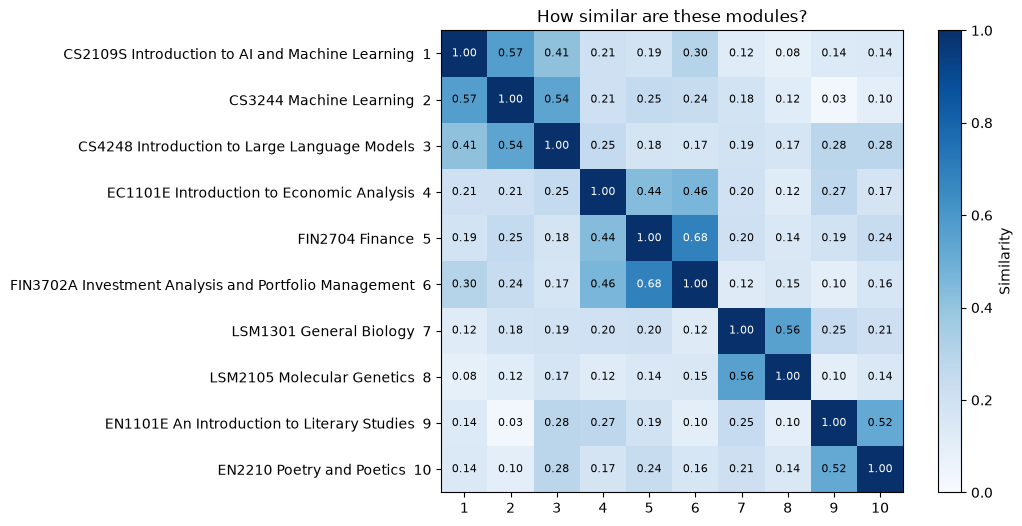

In [157]:
def plot_similarity(labels, vectors, title):
    """Heatmap of the similarity between every pair of vectors."""
    similarity = vectors @ vectors.T
    count = len(labels)

    fig, ax = plt.subplots(figsize=(9, 6))
    image = ax.imshow(similarity, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(count), range(1, count + 1))
    ax.set_yticks(range(count), [f"{label}  {i + 1}" for i, label in enumerate(labels)])
    for i in range(count):
        for j in range(count):
            colour = "white" if similarity[i, j] > 0.6 else "black"
            ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=8, color=colour)
    fig.colorbar(image, label="Similarity")
    ax.set_title(title)
    plt.show()


codes = [
    "CS2109S", "CS3244", "CS4248",     # AI
    "EC1101E", "FIN2704", "FIN3702A",  # economics and finance
    "LSM1301", "LSM2105",              # biology
    "EN1101E", "EN2210",               # literature
]
rows = [row_of[code] for code in codes]
labels = [f"{code} {modules[row]['title']}" for code, row in zip(codes, rows)]

plot_similarity(labels, embeddings[rows], "How similar are these modules?")

**How to read it:** each cell compares two modules, and a darker cell means more similar. The diagonal is every module against itself, so it is always 1.00.

The darker squares along the diagonal are the four areas: AI, economics and finance, biology, and literature. Nobody told the model which faculty a module belongs to. It grouped them from the text alone.

Unrelated modules do not score 0. They mostly sit around 0.1 to 0.3, so read the scores as a ranking: related pairs score higher than unrelated ones.

**Think about it:** find CS4248, the large language models module. How does it score against the two literature modules, compared with FIN2704? What might the model be picking up?

**YOUR TURN:** edit the sentences below and re-run the cell. Which pairs surprise you? Some things to try:

- The same word with two meanings: "I sat by the river bank" and "I opened a bank account".
- Opposites: "I love durian" and "I hate durian".
- The same sentence in two languages.

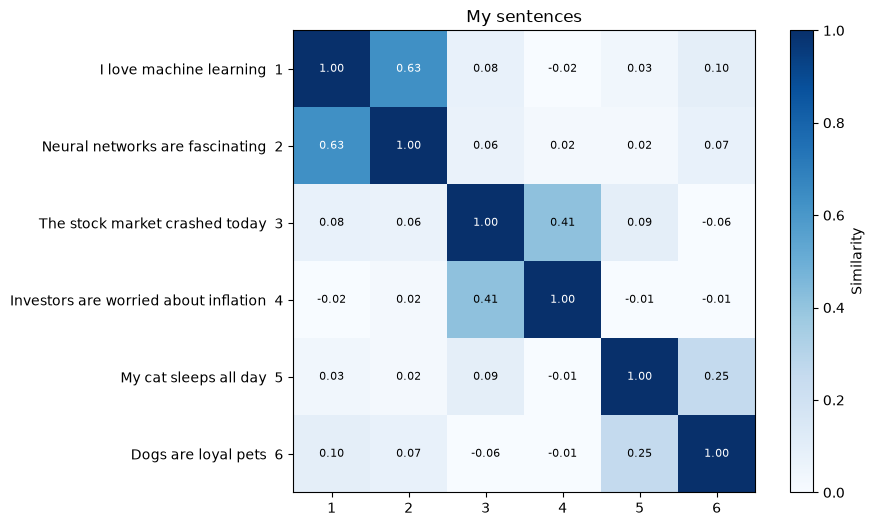

In [158]:
# YOUR TURN: edit these sentences, then re-run
my_sentences = [
    "I love machine learning",
    "Neural networks are fascinating",
    "The stock market crashed today",
    "Investors are worried about inflation",
    "My cat sleeps all day",
    "Dogs are loyal pets",
]

plot_similarity(my_sentences, model.encode(my_sentences, normalize_embeddings=True), "My sentences")

## 2.2 Chunking

We can now turn any text into a vector. But how much text should go into each vector: a whole handbook, one page, or one sentence?

A **chunk** is one piece of text that gets its own vector. Real sources such as a handbook, a PDF or a website are too long to embed in one go, so we split them. There are two reasons:

- **Token budget:** MiniLM reads at most 256 tokens. Anything after that is silently cut off.
- **Precision:** one vector has to summarise the whole chunk. A vector for a 50-page handbook is about everything, so it is not close to any particular question.

Too small hurts too. A chunk that holds only a workload line has lost the module it belongs to. Aim for one self-contained idea per chunk.

Common ways to split:

- **Fixed size:** cut every N tokens.
- **Fixed size with overlap:** neighbouring chunks share some tokens, so a sentence cut at one boundary still appears whole in the next chunk.
- **By structure:** cut at natural boundaries such as sections or paragraphs.

NUSMods is a lucky case. The data is already split by structure, and each module is short and self-contained, so **one module = one chunk**. The decision left is which fields of a module go into the chunk text.

In [159]:
module = modules[row_of["CS2040S"]]

print("The raw module:")
for field, value in module.items():
    print(f"  {field}: {value}")

print()
print("The chunk that gets embedded:")
print(build_chunk(module))

The raw module:
  moduleCode: CS2040S
  title: Data Structures and Algorithms
  description: This course introduces students to the design and implementation of fundamental data structures and algorithms. The course covers basic data structures (linked lists, stacks, queues, hash tables, binary heaps, trees, and graphs), searching and sorting algorithms, and basic analysis of algorithms.
  workload: [3, 0, 1, 3, 3]
  prerequisite: If undertaking an Undergraduate DegreeTHEN( must have completed 1 of CS1010/CS1010A/CS1010E/CS1010HS/CS1010J/CS1010S/CS1010X/CS1101S/UTC2851 at a grade of at least DANDmust have completed 1 of CS1231/CS1231S/MA1100/MA1100T at a grade of at least D)
  faculty: Computing
  department: Computer Science
  moduleCredit: 4
  semesters: [1, 2]
  hasExam: True

The chunk that gets embedded:
CS2040S
Data Structures and Algorithms
This course introduces students to the design and implementation of fundamental data structures and algorithms. The course covers basic data

`build_chunk` (in `rag_utils.py`) joins four fields with line breaks: code, title, description and workload.

Look at the workload. NUSMods stores it as `[3, 0, 1, 3, 3]`, which tells an embedding model nothing, so we write it out in words first. Preparing text so that the model can use it is part of chunking.

How close are we to the token budget?

In [160]:
chunks = [build_chunk(module) for module in modules]
lengths = [len(ids) for ids in model.tokenizer(chunks, verbose=False)["input_ids"]]

print("CS2040S chunk:", lengths[row_of["CS2040S"]], "tokens. The limit is", model.max_seq_length)
print("Typical chunk:", int(np.median(lengths)), "tokens")

too_long = sum(length > model.max_seq_length for length in lengths)
print(f"{too_long} of {len(modules)} chunks are over the limit and lose their ending")

CS2040S chunk: 83 tokens. The limit is 256
Typical chunk: 134 tokens
99 of 6552 chunks are over the limit and lose their ending


Only a small share of chunks get cut. When it happens, the end of the description and the workload are lost. That is why the code and title go first.

### What we left out

NUSMods has 21,160 modules on record for AY 2026-2027. We kept 6,552:

- **14,382 dropped** because they are not offered this year.
- **226 dropped** because the description is a placeholder such as "Not Available". With nothing to describe the module, its vector would come from the code and title alone.

### Which fields go in?

Adding a field is not free. To see why, we embed the same modules twice: once with the default chunk, and once with the prerequisites added.

Re-embedding all 6,552 modules takes minutes on a CPU, so we use the Computing modules only.

In [161]:
computing = [module for module in modules if module["faculty"] == "Computing"]

fields_default = ["moduleCode", "title", "description", "workload"]
fields_prereq = fields_default + ["prerequisite"]

vectors_default = model.encode([build_chunk(m, fields_default) for m in computing], normalize_embeddings=True)
vectors_prereq = model.encode([build_chunk(m, fields_prereq) for m in computing], normalize_embeddings=True)

print(len(computing), "Computing modules embedded twice")
print()
print("A chunk with prerequisites:")
print(build_chunk(module, fields_prereq))

304 Computing modules embedded twice

A chunk with prerequisites:
CS2040S
Data Structures and Algorithms
This course introduces students to the design and implementation of fundamental data structures and algorithms. The course covers basic data structures (linked lists, stacks, queues, hash tables, binary heaps, trees, and graphs), searching and sorting algorithms, and basic analysis of algorithms.
Workload: 3h lecture, 1h lab, 3h project, 3h preparation
Prerequisites: If undertaking an Undergraduate DegreeTHEN( must have completed 1 of CS1010/CS1010A/CS1010E/CS1010HS/CS1010J/CS1010S/CS1010X/CS1101S/UTC2851 at a grade of at least DANDmust have completed 1 of CS1231/CS1231S/MA1100/MA1100T at a grade of at least D)


In [162]:
def compare_chunks(query, needs=None):
    """Search the Computing modules with both versions of the chunk.

    `needs` is a module code. Results that list it as a prerequisite get a tick.
    """
    for name, vectors in [("Default chunk", vectors_default), ("With prerequisites", vectors_prereq)]:
        print(name)
        for result, score in search(query, embeddings=vectors, modules=computing):
            tick = "✓" if needs and needs in result.get("prerequisite", "") else " "
            print(f"  {score:.2f} {tick} {result['moduleCode']:<9} {result['title']}")


compare_chunks("I have completed CS2040S, what next?", needs="CS2040S")

Default chunk
  0.46   CS4350    Game Development Project
  0.44   CS4238    Computer Security Practice
  0.43   CS3240    Interaction Design
  0.43   CS2030S   Programming Methodology II
  0.43 ✓ CS3241    Computer Graphics
With prerequisites
  0.47 ✓ CS5240    Theoretical Foundations in MultiMedia
  0.47 ✓ CS3241    Computer Graphics
  0.46   CS2030S   Programming Methodology II
  0.46   CS3240    Interaction Design
  0.46 ✓ CS4215    Programming Language Implementation


A tick marks a module that really does list CS2040S as a prerequisite. With the prerequisites in the chunk, more of the top 5 are correct, because the text the question is about is now there to be matched.

Now a question about a topic.

In [163]:
compare_chunks("I want to learn machine learning")

Default chunk
  0.66   CS6216    Advanced Topics in Machine Learning
  0.64   IS2109    AI and Machine Learning Techniques I
  0.64   CS3264    Foundations of Machine Learning
  0.64   CS3244    Machine Learning
  0.57   IS3109    AI and Machine Learning Techniques II
With prerequisites
  0.62   CS6216    Advanced Topics in Machine Learning
  0.60   CS3264    Foundations of Machine Learning
  0.56   IS2109    AI and Machine Learning Techniques I
  0.56   MSI5001   Introduction to AI: Concepts, Applications, and Evaluation
  0.55   IS3109    AI and Machine Learning Techniques II


Every score dropped, and CS3244 Machine Learning, the module with exactly that title, fell out of the top 5. Its prerequisite text is long, and those words now share the vector with the topic.

That is the tradeoff: a field you add helps the questions about that field and dilutes everything else. Longer chunks also push more modules past the 256-token limit. Most questions are about topics, so the default chunk leaves prerequisites out.

**YOUR TURN:** choose your own fields below, re-embed the Computing modules, and compare with the default chunk. Does a shorter chunk do better or worse on your question?

In [164]:
# YOUR TURN: choose the fields and the question, then re-run
# Fields you can use: moduleCode, title, description, workload, prerequisite, faculty, department
my_fields = ["title", "description"]
my_question = "I want to learn machine learning"

my_vectors = model.encode([build_chunk(m, my_fields) for m in computing], normalize_embeddings=True)

print("Default chunk")
show(search(my_question, embeddings=vectors_default, modules=computing))
print("My chunk:", my_fields)
show(search(my_question, embeddings=my_vectors, modules=computing))

Default chunk
  0.66  CS6216    Advanced Topics in Machine Learning
  0.64  IS2109    AI and Machine Learning Techniques I
  0.64  CS3264    Foundations of Machine Learning
  0.64  CS3244    Machine Learning
  0.57  IS3109    AI and Machine Learning Techniques II
My chunk: ['title', 'description']
  0.72  CS3244    Machine Learning
  0.69  IS2109    AI and Machine Learning Techniques I
  0.66  CS6216    Advanced Topics in Machine Learning
  0.64  IS3109    AI and Machine Learning Techniques II
  0.64  CS3264    Foundations of Machine Learning


## 2.3 Retrieval

We have chunks and their vectors. Now: which chunks best answer a question?

1. Embed every chunk once, ahead of time. That is `embeddings`.
2. Embed the query with the same model.
3. Compare the query with every module vector.
4. Sort by score and take the top `k`.

Step 1 is why search is fast: when a question comes in, only the query gets embedded.

In [165]:
def my_search(query, k=5):
    query_vector = model.encode(query, normalize_embeddings=True)  # 2. embed the query
    scores = embeddings @ query_vector                             # 3. compare with every module
    top = np.argsort(-scores)[:k]                                  # 4. sort, take the top k
    return [(modules[i], float(scores[i])) for i in top]

That is the whole retrieval engine, and it is what `search` in `rag_utils.py` does.

**Why `embeddings @ query_vector` is cosine similarity:** with `normalize_embeddings=True`, every vector has length 1. The bottom of the cosine formula becomes 1, so cosine similarity is just the dot product. The line `embeddings @ query_vector` is one matrix multiplication that computes all 6,552 dot products at once. This only works because the module vectors were normalized too.

### Ctrl+F, again

Back to the query that returned nothing in Section 1.

In [166]:
query = "how computers understand language"

print("Keyword search:", len(keyword_search(query)), "matches")
print("My search:")
show(my_search(query))

Keyword search: 5 matches
My search:
  0.63  HS2914    How to Get Humans and Machines to Talk to Each Other
  0.59  EL2206    Language and Cognition
  0.52  EL1101E   The Nature of Language
  0.50  GET1036   The Logic of Language
  0.49  ELC5207   Second Language Acquisition and Processing


Keyword search finds nothing, because no description contains that exact phrase. Your search returns modules about language, and the top hit is a course on how humans and machines handle language.

**Think about it:** most of the results are linguistics modules, not computing ones. Which words in the query pulled them in?

### Do we need a vector database?

In [167]:
import time

query_vector = model.encode("how computers understand language", normalize_embeddings=True)

start = time.perf_counter()
scores = embeddings @ query_vector
top = np.argsort(-scores)[:5]
elapsed_ms = (time.perf_counter() - start) * 1000

print(f"Compared the query with {len(modules)} modules in {elapsed_ms:.1f} ms")

Compared the query with 6552 modules in 0.6 ms


No. A vector database earns its place at millions of chunks, where comparing against everything becomes too slow. For a few thousand chunks, plain numpy is enough.

### Limits

Semantic search won on the opening query. Now a query where the exact word matters, with keyword search and semantic search side by side.

In [168]:
def compare(query, k=5):
    """Show keyword search and semantic search for the same query."""
    matches = keyword_search(query)
    print(f"Keyword search: {len(matches)} matches")
    for match in matches[:k]:
        print(f"        {match['moduleCode']:<9} {match['title']}")
    print("Semantic search:")
    show(search(query, k))


compare("ChatGPT")

Keyword search: 4 matches
        BMS5121   Digital Transformation in The Era of Artificial Intelligence
        DBA4714   Deep Learning and Generative AI in Business
        MKT4761K  Seminars in Marketing: Marketing Technology
        PP5538    Digital Technologies and Public Policy
Semantic search:
  0.38  MKT4761K  Seminars in Marketing: Marketing Technology
  0.37  BME5404   Communications, Influence and Negotiations
  0.35  BME5044   Communications, Influence and Negotiations
  0.34  TTG2901   Communications for Engineering Professionals
  0.34  NM1101E   Communications, New Media and Society


Keyword search wins this one. Four descriptions mention ChatGPT by name, and Ctrl+F finds all of them. Semantic search finds one, then fills the other slots with communication modules.

Why? MiniLM was trained before ChatGPT existed, so it has never seen the word. This is how its tokenizer reads it:

In [169]:
print(model.tokenizer.tokenize("ChatGPT"))

['chat', '##gp', '##t']


The model sees "chat" plus two fragments, the same splitting you saw in 2.1, so it goes looking for modules about communication. The embedding model has a knowledge cutoff too, just like the LLM in Section 1.

| | Keyword search | Semantic search |
|---|---|---|
| Matches | exact words | similar meaning |
| Good at | names, rare terms, new words | paraphrases and vague questions |
| Fails when | you use different words from the text | the exact word matters, or the model has never seen it |
| Returns | every match, in no particular order | always `k` results, ranked by score |

The last row matters: semantic search **always** returns `k` modules, even when nothing relevant exists.

### Hybrid search

Each method fails exactly where the other is strong. Remember BM25 from 2.1: it ranks results like semantic search, but it scores exact words, so it handles codes, names and new words such as ChatGPT. Real systems run both and merge the two rankings, so a module comes out on top if it matches the words or the meaning. This is called **hybrid search**.

Our engine uses semantic search only, so expect it to miss exact words.

**YOUR TURN:** ask your own questions. Some things to try:

- A topic in your own words, the way you would ask a senior.
- A module code, such as `CS2040S`.
- A greeting, such as `hi`.
- A filter, such as `4 MC, no exam, semester 2`.
- A larger `k`. Do the extra results still look relevant?

**Keep your funniest failure.** We will collect them in Section 3.

In [170]:
# YOUR TURN: ask your own question, and change k
my_query = "I want to learn how to invest"
k = 5

compare(my_query, k)

Keyword search: 5 matches
        CCS5206   How to Live Well on a Damaged Planet
        NHS2096   How to escape despotism?
        HS2914    How to Get Humans and Machines to Talk to Each Other
        CMH5102   Mental Health Conditions I
        CMH5104   Management of Mental Health Conditions I
Semantic search:
  0.62  BMF5332   Foundation of Investments
  0.62  FIN4716   Equity Research Seminar
  0.60  FIN3702A  Investment Analysis and Portfolio Management
  0.60  FIN3702B  Investment Analysis and Portfolio Management
  0.60  BME5302   Investment Management


## Recap

- **Words as vectors:** TF-IDF and BM25 rank modules by shared words, so a paraphrase with different words scores 0.
- **Embedding:** a model turns text into a vector, similar meanings land close together, and cosine similarity measures how close.
- **Chunking:** one module is one chunk, and the fields you put in the chunk decide what it can be found by.
- **Retrieval:** embed the query, take a dot product with every module, sort, and keep the top `k`.
- **Hybrid search:** real systems combine BM25 for exact words with embeddings for meaning.

Section 3 takes the modules returned by `search(query, k=5)` and hands them to Gemini.

### If you're stuck

Run the cell below. It reloads everything Section 3 needs.

In [171]:
# Reloads the data, the embedding model, Gemini and the helpers from Sections 1 and 2 if anything above failed
import re
import textwrap

from IPython.display import Markdown, display

import rag_utils
from rag_utils import ask_gemini, search

modules, embeddings, model = rag_utils.load()
by_code = {module["moduleCode"]: module for module in modules}
rag_utils.connect_gemini()

# From Section 1.5
MODULE_CODE = re.compile(r"\b[A-Z]{2,4}\d{4}[A-Z]{0,2}\b")  # e.g. CS4248, CS2103T

def verify(answer):
    """Look up every module code in the answer in the real NUSMods data."""
    codes = list(dict.fromkeys(MODULE_CODE.findall(answer)))  # unique, in order
    for code in codes:
        real = by_code.get(code)
        if real:
            print(f"  ✅ {code:<9} real title: {real['title']}")
        else:
            print(f"  ❌ {code:<9} not offered in AY {rag_utils.AY}, or does not exist")
        said = next(line for line in answer.splitlines() if code in line)  # where Gemini mentioned it
        print(f"{'':15}Gemini wrote: {textwrap.shorten(re.sub(r'[*_#`|>]', '', said), 90)}")
    print()
    print(f"{sum(code in by_code for code in codes)} of {len(codes)} module codes are real.")

# From Section 2
def show(results):
    """Print (module, score) pairs, one per line."""
    for module, score in results:
        print(f"  {score:.2f}  {module['moduleCode']:<9} {module['title']}")

print(len(modules), "modules, embeddings", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

6552 modules, embeddings (6552, 384)


# Section 3 - Generation + Evaluation

Section 2 built the retriever. This section finishes the RAG pipeline from Section 1.6, then checks how well the retriever works:

1. **Generation:** paste the retrieved modules into the prompt (step 3, *augment*) and let Gemini answer from them (step 4, *generate*).
2. **Evaluation:** measure how often the retriever finds the right module, because the answer can only be as good as what was retrieved.

## 3.1 Generation

Two small functions do the augment step:

- `make_context` turns the `(module, score)` pairs from `search` into plain text, one numbered block per module.
- `build_prompt` wraps that text in instructions: answer **only** from the context, say so when the context is not enough, and cite module codes in square brackets.

In [172]:
import importlib
import rag_utils

importlib.reload(rag_utils)

rag_utils.load()
def make_context(results):
    """Format retrieved (module, score) pairs as numbered text blocks."""
    blocks = []
    for rank, (module, score) in enumerate(results, start=1):
        lines = [
            f"[{rank}] {module['moduleCode']} - {module['title']}",
            f"Description: {module['description']}",
        ]
        workload = rag_utils.format_workload(module.get("workload"))
        if workload:
            lines.append(f"Workload: {workload}")
        if module.get("semesters"):
            lines.append(f"Semesters offered in AY {rag_utils.AY}: {', '.join(map(str, module['semesters']))}")
        if module.get("hasExam") is not None:
            lines.append(f"Has final exam: {'yes' if module['hasExam'] else 'no'}")
        lines.append(f"Retrieval similarity: {score:.3f}")
        blocks.append("\n".join(lines))
    return "\n\n".join(blocks) if blocks else "No modules were retrieved."


def build_prompt(question, context):
    """Wrap the question and the retrieved context in grounding instructions."""
    return f"""You are a helpful assistant answering questions about NUS modules.
Answer the user's question using only the supplied NUSMods context.

Rules:
- If the context does not contain enough evidence, say that the information is not available in the supplied context.
- Do not invent module codes, titles, prerequisites, workload hours, semesters, or exam details.
- When making a claim about a module, cite its module code in square brackets, e.g. [CS1231S].
- Keep the answer concise and distinguish explicit facts from uncertainty.
- The retrieval similarity score is not evidence that a claim is true.

Retrieved context:
{context}

User question: {question}

Answer:"""


def rag_answer(question, k=5, results=None, show_prompt=False):
    """Retrieve, augment, generate. Pass `results` to supply your own context."""
    if results is None:
        results = search(question, k=k)
    prompt = build_prompt(question, make_context(results))
    if show_prompt:
        print(prompt)
        print("-" * 60)
    answer = ask_gemini(prompt)
    display(Markdown(answer))
    return answer

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

### The same question, now with RAG

In Section 1.5, Gemini answered this question from memory, and `verify` caught the module codes it got wrong. Here is the exact prompt RAG sends for the same question. Gemini sees only this text.

In [173]:
question = "Which NUS modules cover attention mechanisms? List the module codes and titles."

print(build_prompt(question, make_context(search(question, k=5))))

You are a helpful assistant answering questions about NUS modules.
Answer the user's question using only the supplied NUSMods context.

Rules:
- If the context does not contain enough evidence, say that the information is not available in the supplied context.
- Do not invent module codes, titles, prerequisites, workload hours, semesters, or exam details.
- When making a claim about a module, cite its module code in square brackets, e.g. [CS1231S].
- Keep the answer concise and distinguish explicit facts from uncertainty.
- The retrieval similarity score is not evidence that a claim is true.

Retrieved context:
[1] PL3281A - Lab in Perception and Attention
Description: The focus of this lab will be perception and attention. Students will be introduced to the different methodologies used in cognitive research such as classical psychophysics, signal detection theory, and reaction time paradigms. Selected topics on perception and attention will be used to illustrate these methods.
Workloa

In [174]:
answer = rag_answer(question)
print("-" * 60)
verify(answer)

Based on the supplied context, the module that covers attention is:

* [PL3281A] Lab in Perception and Attention

------------------------------------------------------------
  ✅ PL3281A   real title: Lab in Perception and Attention
               Gemini wrote: [PL3281A] Lab in Perception and Attention

1 of 1 module codes are real.


Every module code Gemini can cite now comes from the context, so `verify` should find each one in the real data. Compare this with the 1.5 result.

That fixes invented codes, but not missing ones. Look back at the retrieved modules in the prompt: are they about attention in neural networks, or attention in psychology? If the right module was not retrieved, Gemini cannot mention it. The answer is only as good as the context.

### Wrong context, confident answer

To see how much the answer depends on retrieval, keep the question and swap in modules retrieved for an unrelated topic.

In [175]:
wrong_results = search("modules about economics and financial markets", k=5)
show(wrong_results)
print("-" * 60)

wrong_answer = rag_answer(question, results=wrong_results)

  0.59  BMS5307   Financial Markets and Institutions
  0.59  EC5880    Topics in Economics
  0.59  BMD5301   Introduction to Finance for FinTech Professionals
  0.58  FE5213    Quantitative Macroeconomics and Finance with Python
  0.57  EC1101E   Introduction to Economic Analysis
------------------------------------------------------------


The information regarding which modules cover attention mechanisms is not available in the supplied context.

**How to read it:** the prompt tells Gemini to say when the context is not enough. Check whether it did, or whether it stretched an economics module to fit a question about attention mechanisms. Either way, generation cannot recover from bad retrieval, which is why 3.2 measures the retriever on its own.

**YOUR TURN:** ask your own question. Set `show_prompt=True` to see exactly what Gemini received, and change `k` to give it more or fewer modules.

In [176]:
# YOUR TURN: ask your own question, then re-run
my_question = "Which NUS modules teach reinforcement learning? List the module codes and titles."

my_answer = rag_answer(my_question, k=5, show_prompt=False)
print("-" * 60)
verify(my_answer)

Based on the provided context, the following modules teach reinforcement learning:

* [CEG5301] - Machine Learning with Applications [1]
* [IE5603] - Statistical Learning in Engineering II [2]
* [RB4301] - Robot Learning [3]
* [RB3301] - Introduction to Machine Intelligence [4]
* [CS5446] - Reinforcement Learning and Sequential Decision Making [5]

------------------------------------------------------------
  ✅ CEG5301   real title: Machine Learning with Applications
               Gemini wrote: [CEG5301] - Machine Learning with Applications [1]
  ✅ IE5603    real title: Statistical Learning in Engineering II
               Gemini wrote: [IE5603] - Statistical Learning in Engineering II [2]
  ✅ RB4301    real title: Robot Learning
               Gemini wrote: [RB4301] - Robot Learning [3]
  ✅ RB3301    real title: Introduction to Machine Intelligence
               Gemini wrote: [RB3301] - Introduction to Machine Intelligence [4]
  ✅ CS5446    real title: Reinforcement Learning and Sequential Decision Making
               Gemini wrote: [CS5446] - Reinforcement Learning and Sequential Decision Making [5]

5 of 5 module codes are real.


## 3.2 Evaluation

Now we evaluate how effectively our RAG system retrieves the correct NUS module for a user's question.

For each query, we specify the expected module code and compare it with the modules returned by our retrieval system.

We use two metrics:

- **Hit@5:** Measures the proportion of queries for which the correct module appears in the top five retrieved results.
- **Mean Reciprocal Rank (MRR):** Measures how highly the correct module is ranked, rewarding results that appear closer to the top.

These metrics help us assess retrieval performance before investigating potential improvements.

In [177]:
import pandas as pd

workshop_dir = rag_utils.DATA_DIR.parent  # the week-11-nlp folder

In [178]:
eval_path = workshop_dir / "data" / "eval_set_v2.csv"

eval_df = pd.read_csv(eval_path)

print(f"Total evaluation queries: {len(eval_df)}")
print("\nQueries by category:")
display(eval_df["category"].value_counts().to_frame("count"))

display(eval_df.head())

Total evaluation queries: 40

Queries by category:


,count
category,
paraphrase,10
keyword,10
vague,10
prerequisite,10


,query,relevant,category
0,I want to study how computers process human la...,CS4248|DSA4213|CP4284,paraphrase
1,how do apps like Google Lens recognise what's ...,CS4243|EE4212|CS4277|EE4704,paraphrase
2,teach an AI agent to learn by trial and error ...,CS4246|MA4275,paraphrase
3,how to store and query data for a website back...,CS2102|IT2002|TCX2003|TIC2601,paraphrase
4,what happens inside my laptop when I run sever...,CS2106|CG2271,paraphrase


In [179]:
def evaluate_multilabel_retrieval(eval_df, k=5):
    details = []

    for _, row in eval_df.iterrows():
        query = str(row["query"])

        relevant_codes = {
            code.strip().upper()
            for code in str(row["relevant"]).split("|")
            if code.strip()
        }

        results = rag_utils.search(query, k=k)

        ranked_codes = [
            str(module.get("moduleCode", "")).upper()
            for module, score in results
        ]

        # Find ranks of retrieved relevant modules
        relevant_ranks = [
            rank
            for rank, code in enumerate(ranked_codes, start=1)
            if code in relevant_codes
        ]

        first_relevant_rank = (
            min(relevant_ranks) if relevant_ranks else 0
        )

        # Hit@k: at least one relevant module appears in top k
        hit_at_k = int(bool(relevant_ranks))

        # Recall@k: fraction of all relevant modules retrieved in top k
        recall_at_k = (
            len(set(ranked_codes) & relevant_codes) / len(relevant_codes)
            if relevant_codes else 0
        )

        # Reciprocal rank of the first relevant result
        reciprocal_rank = (
            1 / first_relevant_rank
            if first_relevant_rank else 0
        )

        details.append({
            "query": query,
            "category": row["category"],
            "relevant_codes": " | ".join(sorted(relevant_codes)),
            "top_k_module_codes": " | ".join(ranked_codes),
            "rank_of_first_relevant": first_relevant_rank,
            f"hit_at_{k}": hit_at_k,
            f"recall_at_{k}": recall_at_k,
            "reciprocal_rank": reciprocal_rank
        })

    details_df = pd.DataFrame(details)

    summary = {
        "n_queries": len(details_df),
        f"hit_at_{k}": details_df[f"hit_at_{k}"].mean(),
        f"recall_at_{k}": details_df[f"recall_at_{k}"].mean(),
        "mrr": details_df["reciprocal_rank"].mean()
    }

    return summary, details_df

In [180]:
summary, details_df = evaluate_multilabel_retrieval(
    eval_df,
    k=5
)

print(f"Queries evaluated: {summary['n_queries']}")
print(f"Hit@5: {summary['hit_at_5']:.3f}")
print(f"Recall@5: {summary['recall_at_5']:.3f}")
print(f"MRR: {summary['mrr']:.3f}")

results_dir = workshop_dir / "evaluation"
results_dir.mkdir(parents=True, exist_ok=True)

output_path = results_dir / "eval_set_v2_results.csv"
details_df.to_csv(output_path, index=False)

print(f"Results saved to: {output_path}")

display(details_df)

Queries evaluated: 40
Hit@5: 0.600
Recall@5: 0.392
MRR: 0.422
Results saved to: /Users/dharshiniilangovan/Downloads/NLP-Worshop/week-11-nlp/evaluation/eval_set_v2_results.csv


,query,category,relevant_codes,top_k_module_codes,rank_of_first_relevant,hit_at_5,recall_at_5,reciprocal_rank
0,I want to study how computers process human la...,paraphrase,CP4284 | CS4248 | DSA4213,HS2914 | PL3281E | EL2206 | EL1101E | EL3206,0,0,0.000000,0.000000
1,how do apps like Google Lens recognise what's ...,paraphrase,CS4243 | CS4277 | EE4212 | EE4704,NST2050 | EE6733 | EE4212 | AIS5202 | CS5240,3,1,0.250000,0.333333
2,teach an AI agent to learn by trial and error ...,paraphrase,CS4246 | MA4275,CS3227 | TCX2006 | IS4403 | EE2213 | MSI5001,0,0,0.000000,0.000000
3,how to store and query data for a website back...,paraphrase,CS2102 | IT2002 | TCX2003 | TIC2601,TIC2601 | DSA5104 | CS3223 | IT2002 | TCX2003,1,1,0.750000,1.000000
4,what happens inside my laptop when I run sever...,paraphrase,CG2271 | CS2106,CS6215 | CS5218 | CS5239 | CS3210 | CS2100DE,0,0,0.000000,0.000000
5,how does code I write get translated into mach...,paraphrase,CS4212,GET1036 | CS4215 | CS4212 | GEX1019 | HS2914,3,1,1.000000,0.333333
6,how do I keep messages secret so only the rece...,paraphrase,CS4230 | CS4236,CS4230 | CS5430 | SWE5005G | SWE5005 | CS3236,1,1,0.500000,1.000000
7,I want to build my own video game,paraphrase,CS3247 | CS4350 | NM4260,CS4350 | NM4260 | CS3247 | HY2272 | ME5612,1,1,1.000000,1.000000
8,working in a team to build a large software pr...,paraphrase,CS2103 | CS2103DE | CS2103R | CS2103T | CS2113...,MLE4102A | SWE5007 | CS3216 | CDE3301 | TCX3224,0,0,0.000000,0.000000
9,how cryptocurrency and Bitcoin actually work,paraphrase,FIN4724 | IS4302,QF4211 | DSE4211 | CS4236 | FIN4724 | FT5003,4,1,0.500000,0.250000


In [181]:
import pandas as pd
from IPython.display import display

# Class-wise evaluation
classwise_summary = (
    details_df
    .groupby("category")
    .agg(
        queries=("query", "count"),
        hit_at_5=("hit_at_5", "mean"),
        recall_at_5=("recall_at_5", "mean"),
        mrr=("reciprocal_rank", "mean")
    )
    .reset_index()
)

# Convert metrics to percentages where appropriate
classwise_summary["hit_at_5"] *= 100
classwise_summary["recall_at_5"] *= 100

# Round results
classwise_summary = classwise_summary.round({
    "hit_at_5": 2,
    "recall_at_5": 2,
    "mrr": 3
})

print("Class-wise Retrieval Evaluation Results")
display(classwise_summary)

Class-wise Retrieval Evaluation Results


,category,queries,hit_at_5,recall_at_5,mrr
0,keyword,10,100.0,67.50,0.670
1,paraphrase,10,60.0,40.00,0.392
2,prerequisite,10,60.0,34.17,0.425
3,vague,10,20.0,15.00,0.200


In [182]:
query = "how computers understand language"

# 1. Keyword search
print("=== KEYWORD SEARCH ===")
keyword_results = rag_utils.keyword_search(query, k=5)

if keyword_results:
    for module in keyword_results:
        print(f"{module['moduleCode']} - {module['title']}")
else:
    print("No keyword matches found.")

# 2. Semantic search
print("\n=== SEMANTIC SEARCH ===")
semantic_results = rag_utils.search(query, k=5)

for module, score in semantic_results:
    print(
        f"{module['moduleCode']} - "
        f"{module['title']} (score: {score:.3f})"
    )

=== KEYWORD SEARCH ===
CL3215 - Chinese Language and Culture
GET1036 - The Logic of Language
GEX1019 - The Logic of Language
HS2914 - How to Get Humans and Machines to Talk to Each Other
UTW1001V - Am I Who I Am? Knowledge, Language and Identity

=== SEMANTIC SEARCH ===
HS2914 - How to Get Humans and Machines to Talk to Each Other (score: 0.628)
EL2206 - Language and Cognition (score: 0.589)
EL1101E - The Nature of Language (score: 0.518)
GET1036 - The Logic of Language (score: 0.502)
ELC5207 - Second Language Acquisition and Processing (score: 0.489)


In [183]:
import importlib
import rag_utils

# Reload the latest keyword_search implementation
importlib.reload(rag_utils)

# Load modules, embeddings, and model AFTER reloading
modules, embeddings, model = rag_utils.load()

print("Modules loaded:", rag_utils.modules is not None)
print("Number of modules:", len(rag_utils.modules))
print("Embeddings shape:", rag_utils.embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Modules loaded: True
Number of modules: 6552
Embeddings shape: (6552, 384)


What can we learn?

Keyword search matches individual words in titles and descriptions. It may return modules that mention language without addressing the user's actual intent.



Semantic search uses embeddings to identify conceptually related modules. Here, it ranks HS2914 first, which appears more directly related to communication between humans and machines.



Both methods retrieve GET1036, showing some overlap between their results.

In [184]:
import pandas as pd

def evaluate_retriever(eval_df, method="semantic", k=5):
    details = []

    for _, row in eval_df.iterrows():
        query = str(row["query"])

        relevant_codes = {
            code.strip().upper()
            for code in str(row["relevant"]).split("|")
            if code.strip()
        }

        # Run selected retriever
        if method == "keyword":
            results = rag_utils.keyword_search(query, k=k)

            ranked_codes = [
                str(module.get("moduleCode", "")).upper()
                for module in results
            ]

        elif method == "semantic":
            results = rag_utils.search(query, k=k)

            ranked_codes = [
                str(module.get("moduleCode", "")).upper()
                for module, score in results
            ]

        else:
            raise ValueError(
                "method must be 'keyword' or 'semantic'"
            )

        # Rank positions of relevant retrieved modules
        relevant_ranks = [
            rank
            for rank, code in enumerate(ranked_codes, start=1)
            if code in relevant_codes
        ]

        first_relevant_rank = (
            min(relevant_ranks) if relevant_ranks else 0
        )

        # Hit@k: at least one relevant result
        hit_at_k = int(bool(relevant_ranks))

        # Recall@k: relevant retrieved / all labelled relevant
        recall_at_k = (
            len(set(ranked_codes) & relevant_codes)
            / len(relevant_codes)
            if relevant_codes else 0
        )

        # Reciprocal rank of the first relevant result
        reciprocal_rank = (
            1 / first_relevant_rank
            if first_relevant_rank else 0
        )

        details.append({
            "method": method,
            "query": query,
            "category": row["category"],
            "relevant_codes": " | ".join(sorted(relevant_codes)),
            "top_k_module_codes": " | ".join(ranked_codes),
            f"hit_at_{k}": hit_at_k,
            f"recall_at_{k}": recall_at_k,
            "reciprocal_rank": reciprocal_rank,
            "rank_of_first_relevant": first_relevant_rank
        })

    details_df = pd.DataFrame(details)

    summary = {
        "method": method,
        "n_queries": len(details_df),
        f"hit_at_{k}": details_df[f"hit_at_{k}"].mean(),
        f"recall_at_{k}": details_df[f"recall_at_{k}"].mean(),
        "mrr": details_df["reciprocal_rank"].mean()
    }

    return summary, details_df

In [185]:
keyword_summary, keyword_details = evaluate_retriever(
    eval_df,
    method="keyword",
    k=5
)

semantic_summary, semantic_details = evaluate_retriever(
    eval_df,
    method="semantic",
    k=5
)

comparison = pd.DataFrame([
    keyword_summary,
    semantic_summary
])

comparison = comparison.rename(columns={
    "method": "Method",
    "n_queries": "Queries",
    "hit_at_5": "Hit@5",
    "recall_at_5": "Recall@5",
    "mrr": "MRR"
})

print("OVERALL RETRIEVAL COMPARISON")
display(comparison.round(3))

OVERALL RETRIEVAL COMPARISON


,Method,Queries,Hit@5,Recall@5,MRR
0,keyword,40,0.4,0.244,0.260
1,semantic,40,0.6,0.392,0.422


In [186]:
all_details = pd.concat(
    [keyword_details, semantic_details],
    ignore_index=True
)

classwise_comparison = (
    all_details
    .groupby(["category", "method"])
    .agg(
        queries=("query", "count"),
        hit_at_5=("hit_at_5", "mean"),
        recall_at_5=("recall_at_5", "mean"),
        mrr=("reciprocal_rank", "mean")
    )
    .reset_index()
)

classwise_comparison = classwise_comparison.rename(columns={
    "category": "Query Category",
    "method": "Method",
    "queries": "Queries",
    "hit_at_5": "Hit@5",
    "recall_at_5": "Recall@5",
    "mrr": "MRR"
})

print("CLASS-WISE RETRIEVAL COMPARISON")
display(classwise_comparison.round(3))

CLASS-WISE RETRIEVAL COMPARISON


,Query Category,Method,Queries,Hit@5,Recall@5,MRR
0,keyword,keyword,10,1.0,0.750,0.673
1,keyword,semantic,10,1.0,0.675,0.670
2,paraphrase,keyword,10,0.1,0.033,0.033
3,paraphrase,semantic,10,0.6,0.400,0.392
4,prerequisite,keyword,10,0.4,0.092,0.283
5,prerequisite,semantic,10,0.6,0.342,0.425
6,vague,keyword,10,0.1,0.100,0.050
7,vague,semantic,10,0.2,0.150,0.200


- Keyword queries: Both methods achieved Hit@5 of 1.0. Keyword search retrieved a larger proportion of relevant modules.
- Paraphrase queries: Semantic search substantially outperformed keyword matching, which struggles when the wording differs from the module description.
- Prerequisite queries: Semantic search performs better, but it still misses relevant modules. Structured prerequisite information could help.
- Vague queries: Both methods perform poorly. Query expansion or asking users a clarification question may help.


## Interpretation of Retrieval Evaluation Results

### 1. Comparison by Query Category

The evaluation compares keyword-based retrieval and semantic retrieval across four query categories: keyword, paraphrase, prerequisite, and vague queries. The performance is measured using Hit@5, Recall@5, and Mean Reciprocal Rank (MRR).

| Query Category | Method | Hit@5 | Recall@5 | MRR |
|---|---|---:|---:|---:|
| Keyword | Keyword | 1.000 | 0.750 | 0.673 |
| Keyword | Semantic | 1.000 | 0.675 | 0.670 |
| Paraphrase | Keyword | 0.100 | 0.033 | 0.033 |
| Paraphrase | Semantic | 0.600 | 0.400 | 0.392 |
| Prerequisite | Keyword | 0.400 | 0.092 | 0.283 |
| Prerequisite | Semantic | 0.600 | 0.342 | 0.425 |
| Vague | Keyword | 0.100 | 0.100 | 0.050 |
| Vague | Semantic | 0.200 | 0.150 | 0.200 |

### 2. Overall Performance

Since each query category contains 10 queries, the overall metrics can be calculated by taking the average of the four category-level scores.

| Metric | Keyword Retrieval | Semantic Retrieval |
|---|---:|---:|
| Hit@5 | 0.400 | 0.600 |
| Recall@5 | 0.244 | 0.392 |
| MRR | 0.260 | 0.422 |

Semantic retrieval achieves better overall performance, with Hit@5 increasing from 40% to 60%. It also achieves higher Recall@5 and MRR, indicating that it retrieves more relevant modules and tends to rank relevant results higher.

### 3. Observations

- **Keyword queries:** Both methods achieve a Hit@5 of 1.000, meaning that at least one relevant module is retrieved in the top five for every query. Keyword retrieval has slightly higher Recall@5 (0.750 vs. 0.675), while their MRR values are nearly identical.
- **Paraphrase queries:** Semantic retrieval performs substantially better, achieving a Hit@5 of 0.600 compared with 0.100 for keyword retrieval. This demonstrates its ability to retrieve relevant modules when queries use different wording from the module descriptions.
- **Prerequisite queries:** Semantic retrieval achieves a Hit@5 of 0.600, compared with 0.400 for keyword retrieval. It also achieves higher Recall@5 and MRR, suggesting that semantic similarity helps identify conceptually related modules.
- **Vague queries:** Both methods perform poorly. Semantic retrieval achieves a Hit@5 of 0.200, while keyword retrieval achieves 0.100. This suggests that queries with insufficient detail remain challenging for both approaches.

### 4. Conclusion 

The results indicate that semantic retrieval is a stronger baseline for the NUSMods RAG system, particularly for paraphrase and prerequisite queries. However, keyword retrieval remains competitive for queries containing explicit terms that match module titles and descriptions.




**YOUR TURN:** pick a query from the table above that missed (`hit_at_5` is 0), or ask your own question, and look at what the retriever returned instead.

In [187]:
# YOUR TURN: change the question, then re-run
query = "Which NUS modules cover attention mechanisms?"

results = rag_utils.search(query, k=5)

print(f"Query: {query}\n")
print("Top 5 retrieved modules:\n")

for rank, (module, score) in enumerate(results, start=1):
    print(f"{rank}. {module.get('moduleCode', 'N/A')} - "
          f"{module.get('title', 'N/A')}")
    print(f"   Similarity score: {score:.4f}\n")

Query: Which NUS modules cover attention mechanisms?

Top 5 retrieved modules:

1. PL3281A - Lab in Perception and Attention
   Similarity score: 0.4792

2. NRM3302R - NUSC Undergraduate Research Opportunity (S&T UROP)
   Similarity score: 0.4097

3. GEX1009 - Understanding Your Brain
   Similarity score: 0.4058

4. NRM3301R - NUSC Undergraduate Research Opportunity (UROP)
   Similarity score: 0.4056

5. NRM3302 - NUSC Undergraduate Research Opportunity (S&T - UROP))
   Similarity score: 0.3839



## Recap

- **Generation:** the retrieved modules go into the prompt as context, and the instructions keep Gemini to that context and make it cite module codes.
- **Evaluation:** Hit@5 asks whether a relevant module made the top 5; MRR rewards finding it near the top.
- **The weak link is retrieval:** with the wrong context, even a good LLM gives a poor answer.